# EE250 Fall 2026 · Week 1: SFO departure delays

**Slice:** all reported domestic departures from SFO, January–May 2025 (five whole months).
The monthly CSVs contain nationwide rows; we explicitly filter the origin to SFO.
The five-month period reaches the 50,000-flight target but mixes winter and spring conditions.
These are the observed sample for Weeks 1, 2, and 4, not every possible flight or season.

**Definitions:** C = operating carrier (`OP_UNIQUE_CARRIER`); D = departure delay in minutes;
A = arrival delay; L = 1 if D ≥ 15, otherwise 0; H = scheduled local departure hour.
Early departures remain negative. A positive delay (D > 0) is different from being late (D ≥ 15).


In [31]:
from pathlib import Path

# Find the project folder
project_folder = Path.cwd()

# If running inside notebooks, go up one folder
if project_folder.name == "notebooks":
    project_folder = project_folder.parent

# Create the output folders
results_folder = project_folder / "results"
figures_folder = results_folder / "figures"
tables_folder = results_folder / "tables"

figures_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)

print("Saving results to:", results_folder)

Saving results to: /home/sergiorodriguez/Documents/EE250-term-project/results


In [32]:
# Import the libraries we will use
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# Use the same random seed whenever we sample data
np.random.seed(250)

# Folder containing the original CSV files
data_folder = "../data/raw/"

# Read each monthly file
january = pd.read_csv(data_folder + "2025_January.csv")
february = pd.read_csv(data_folder + "2025_February.csv")
march = pd.read_csv(data_folder + "2025_March.csv")
april = pd.read_csv(data_folder + "2025_April.csv")
may = pd.read_csv(data_folder + "2025_May.csv")

# Combine the five months into one table
all_flights = pd.concat(
    [january, february, march, april, may],
    ignore_index=True
)

# Display the number of flights across all airports
print("Flights across all airports:", len(all_flights))

# Select only flights departing from SFO
flights = all_flights[all_flights["ORIGIN"] == "SFO"].copy()

# Display the number of SFO departures
print("SFO departures before cleaning:", len(flights))

# Display the first five rows
display(flights.head())

# Display the column names and their data types
flights.info()

# Display the number of missing values in each column
print("\nMissing values:")
print(flights.isna().sum())

Flights across all airports: 2835101
SFO departures before cleaning: 57720


,YEAR,MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,DEP_DEL15,ARR_DELAY,CANCELLED,DIVERTED
2401,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,17,0.0,0.0,-23.0,0.0,0.0
2402,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,711,-4.0,0.0,-21.0,0.0,0.0
2403,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,900,45.0,1.0,11.0,0.0,0.0
2404,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,1328,11.0,0.0,0.0,0.0,0.0
2405,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,2203,0.0,0.0,-33.0,0.0,0.0


<class 'pandas.DataFrame'>
Index: 57720 entries, 2401 to 2833859
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   YEAR               57720 non-null  int64  
 1   MONTH              57720 non-null  int64  
 2   DAY_OF_WEEK        57720 non-null  int64  
 3   FL_DATE            57720 non-null  str    
 4   OP_UNIQUE_CARRIER  57720 non-null  str    
 5   ORIGIN             57720 non-null  str    
 6   DEST               57720 non-null  str    
 7   CRS_DEP_TIME       57720 non-null  int64  
 8   DEP_DELAY          57391 non-null  float64
 9   DEP_DEL15          57391 non-null  float64
 10  ARR_DELAY          57224 non-null  float64
 11  CANCELLED          57720 non-null  float64
 12  DIVERTED           57720 non-null  float64
dtypes: float64(5), int64(4), str(4)
memory usage: 6.2 MB

Missing values:
YEAR                   0
MONTH                  0
DAY_OF_WEEK            0
FL_DATE                0
OP_UNIQ

## 1. Inspect and combine the files


In [33]:
# Read each monthly CSV file
january = pd.read_csv(data_folder + "2025_January.csv")
february = pd.read_csv(data_folder + "2025_February.csv")
march = pd.read_csv(data_folder + "2025_March.csv")
april = pd.read_csv(data_folder + "2025_April.csv")
may = pd.read_csv(data_folder + "2025_May.csv")

# Combine all five months
all_flights = pd.concat(
    [january, february, march, april, may],
    ignore_index=True
)

print("Total flights:", len(all_flights))

# Keep only departures from SFO
flights = all_flights[all_flights["ORIGIN"] == "SFO"].copy()

print("SFO departures before cleaning:", len(flights))

# Look at the first five rows
display(flights.head())

# Show column names, data types, and non-missing counts
flights.info()

# Count missing values in each column
print("\nMissing values:")
print(flights.isna().sum())

Total flights: 2835101
SFO departures before cleaning: 57720


,YEAR,MONTH,DAY_OF_WEEK,FL_DATE,OP_UNIQUE_CARRIER,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,DEP_DEL15,ARR_DELAY,CANCELLED,DIVERTED
2401,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,17,0.0,0.0,-23.0,0.0,0.0
2402,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,711,-4.0,0.0,-21.0,0.0,0.0
2403,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,900,45.0,1.0,11.0,0.0,0.0
2404,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,1328,11.0,0.0,0.0,0.0,0.0
2405,2025,1,1,1/6/2025 12:00:00 AM,AA,SFO,CLT,2203,0.0,0.0,-33.0,0.0,0.0


<class 'pandas.DataFrame'>
Index: 57720 entries, 2401 to 2833859
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   YEAR               57720 non-null  int64  
 1   MONTH              57720 non-null  int64  
 2   DAY_OF_WEEK        57720 non-null  int64  
 3   FL_DATE            57720 non-null  str    
 4   OP_UNIQUE_CARRIER  57720 non-null  str    
 5   ORIGIN             57720 non-null  str    
 6   DEST               57720 non-null  str    
 7   CRS_DEP_TIME       57720 non-null  int64  
 8   DEP_DELAY          57391 non-null  float64
 9   DEP_DEL15          57391 non-null  float64
 10  ARR_DELAY          57224 non-null  float64
 11  CANCELLED          57720 non-null  float64
 12  DIVERTED           57720 non-null  float64
dtypes: float64(5), int64(4), str(4)
memory usage: 6.2 MB

Missing values:
YEAR                   0
MONTH                  0
DAY_OF_WEEK            0
FL_DATE                0
OP_UNIQ

## 2. Clean and keep an audit trail
First exclude cancellations, then diversions among the remaining flights (so removal counts do not overlap).
Require finite D and A and a carrier, date, and valid scheduled hour to retain a common usable slice for later weeks.
Record these additional exclusions separately. Do not clip delays or trim extreme observations.
Retain identical field combinations: the supplied schema has no unique flight identifier.

In [43]:
# Rename columns to make them easier to use
df = flights.rename(columns={
    "YEAR": "year",
    "MONTH": "month",
    "DAY_OF_WEEK": "day_of_week",
    "FL_DATE": "date",
    "OP_UNIQUE_CARRIER": "carrier",
    "ORIGIN": "origin",
    "DEST": "dest",
    "CRS_DEP_TIME": "scheduled_time",
    "DEP_DELAY": "dep_delay",
    "DEP_DEL15": "bts_late",
    "ARR_DELAY": "arr_delay",
    "CANCELLED": "cancelled",
    "DIVERTED": "diverted"
}).copy()

print("SFO flights before cleaning:", len(df))

# Remove cancelled flights
before = len(df)
df = df[df["cancelled"] == 0].copy()
print("Cancelled flights removed:", before - len(df))

# Remove diverted flights
before = len(df)
df = df[df["diverted"] == 0].copy()
print("Diverted flights removed:", before - len(df))

# Convert the dates from text to dates
df["date"] = pd.to_datetime(
    df["date"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce"
)

# Convert departure and arrival delays to numbers
df["dep_delay"] = pd.to_numeric(df["dep_delay"], errors="coerce")
df["arr_delay"] = pd.to_numeric(df["arr_delay"], errors="coerce")

# Remove flights with missing delays, dates, or carriers
before = len(df)

df = df.dropna(
    subset=["dep_delay", "arr_delay", "date", "carrier"]
).copy()

print("Flights removed for missing information:", before - len(df))

# Convert scheduled departure time to a number
df["scheduled_time"] = pd.to_numeric(
    df["scheduled_time"],
    errors="coerce"
)

# Remove flights with missing scheduled departure times
before = len(df)
df = df.dropna(subset=["scheduled_time"]).copy()
print("Flights removed for missing departure time:", before - len(df))

# Extract the scheduled departure hour
# Example: 1435 // 100 gives 14
df["hour"] = (df["scheduled_time"] // 100).astype(int)

# Treat 2400 as midnight, which is hour 0
df.loc[df["hour"] == 24, "hour"] = 0

# Label flights as late when departure delay is at least 15 minutes
# True becomes 1, and False becomes 0
df["late"] = (df["dep_delay"] >= 15).astype(int)

# Keep negative delays because they represent early departures

# Count the cleaned flights
N = len(df)
print("Final number of flights:", N)

# Display the number of flights in each month
print("\nFlights per month:")
print(df["month"].value_counts().sort_index())

# Display a preview of the cleaned data
display(df.head())

# Create the processed-data folder
processed_folder = project_folder / "data" / "processed"
processed_folder.mkdir(parents=True, exist_ok=True)

# Save the cleaned flights
df.to_csv(
    processed_folder / "2025_jan_may_clean.csv",
    index=False
)

print("Saved cleaned flights:", len(df))

SFO flights before cleaning: 57720
Cancelled flights removed: 343
Diverted flights removed: 153
Flights removed for missing information: 0
Flights removed for missing departure time: 0
Final number of flights: 57224

Flights per month:
month
1    10720
2     9799
3    11780
4    12113
5    12812
Name: count, dtype: int64


,year,month,day_of_week,date,carrier,origin,dest,scheduled_time,dep_delay,bts_late,arr_delay,cancelled,diverted,hour,late
2401,2025,1,1,2025-01-06,AA,SFO,CLT,17,0.0,0.0,-23.0,0.0,0.0,0,0
2402,2025,1,1,2025-01-06,AA,SFO,CLT,711,-4.0,0.0,-21.0,0.0,0.0,7,0
2403,2025,1,1,2025-01-06,AA,SFO,CLT,900,45.0,1.0,11.0,0.0,0.0,9,1
2404,2025,1,1,2025-01-06,AA,SFO,CLT,1328,11.0,0.0,0.0,0.0,0.0,13,0
2405,2025,1,1,2025-01-06,AA,SFO,CLT,2203,0.0,0.0,-33.0,0.0,0.0,22,0


Saved cleaned flights: 57224


## 3. Empirical distribution of lateness L
Each proportion uses all N retained flights as its denominator. A not-late flight may still have a positive delay shorter than 15 minutes.

Total flights: 57224
Late flights: 9558
Not-late flights: 47666
P(L = 1) = 0.167
Percent late: 16.7 %


,Category,Count,Proportion
0,Not late,47666,0.832972
1,Late,9558,0.167028


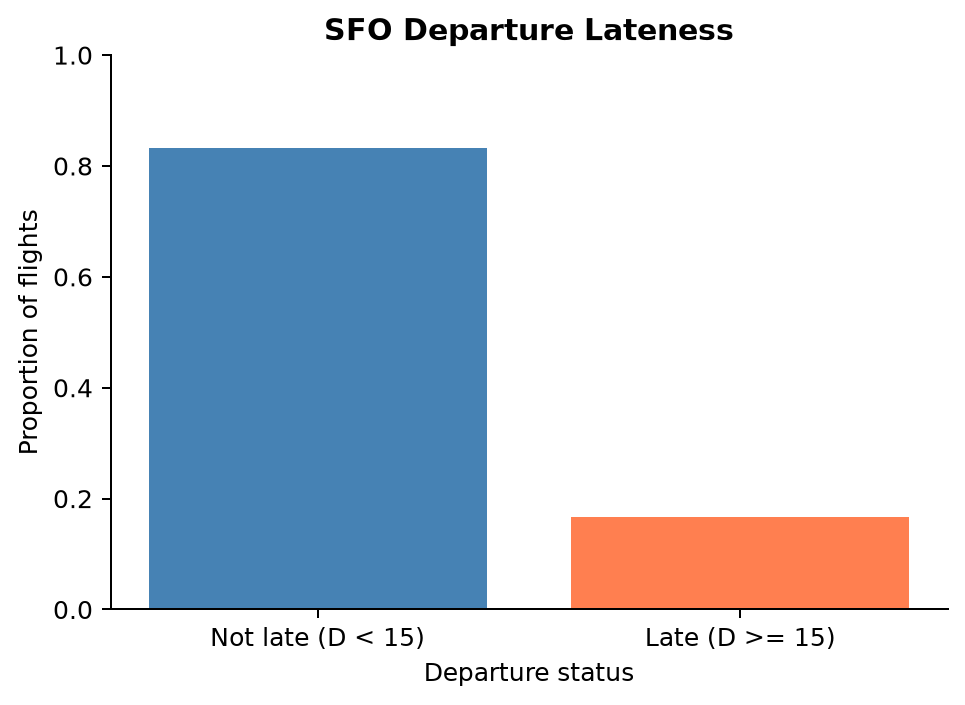

In [35]:
# Count all cleaned flights
N = len(df)

# Count late and not-late flights
late_n = len(df[df["late"] == 1])
not_late_n = len(df[df["late"] == 0])

# Calculate the proportions
p_late = late_n / N
p_not_late = not_late_n / N

# Display the counts and probability
print("Total flights:", N)
print("Late flights:", late_n)
print("Not-late flights:", not_late_n)
print("P(L = 1) =", round(p_late, 4))
print("Percent late:", round(p_late * 100, 2), "%")

# Make a table of counts and proportions
lateness = pd.DataFrame({
    "Category": ["Not late", "Late"],
    "Count": [not_late_n, late_n],
    "Proportion": [p_not_late, p_late]
})

display(lateness)

# Draw a bar chart
plt.figure(figsize=(6, 4))

plt.bar(
    ["Not late (D < 15)", "Late (D >= 15)"],
    [p_not_late, p_late],
    color=["steelblue", "coral"]
)

plt.xlabel("Departure status")
plt.ylabel("Proportion of flights")
plt.title("SFO Departure Lateness")
plt.ylim(0, 1)

# Lateness bar chart
plt.savefig(figures_folder / "lateness.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Departure delay histogram
The first panel retains the entire range, including extreme delays. The second zooms to −30 through 180 minutes
to show the bulk; the excluded-from-view count is printed and those flights remain in every calculation.

count    57224.000000
mean         8.830071
std         47.368610
min        -36.000000
25%         -7.000000
50%         -3.000000
75%          4.000000
max       2117.000000
Name: dep_delay, dtype: float64


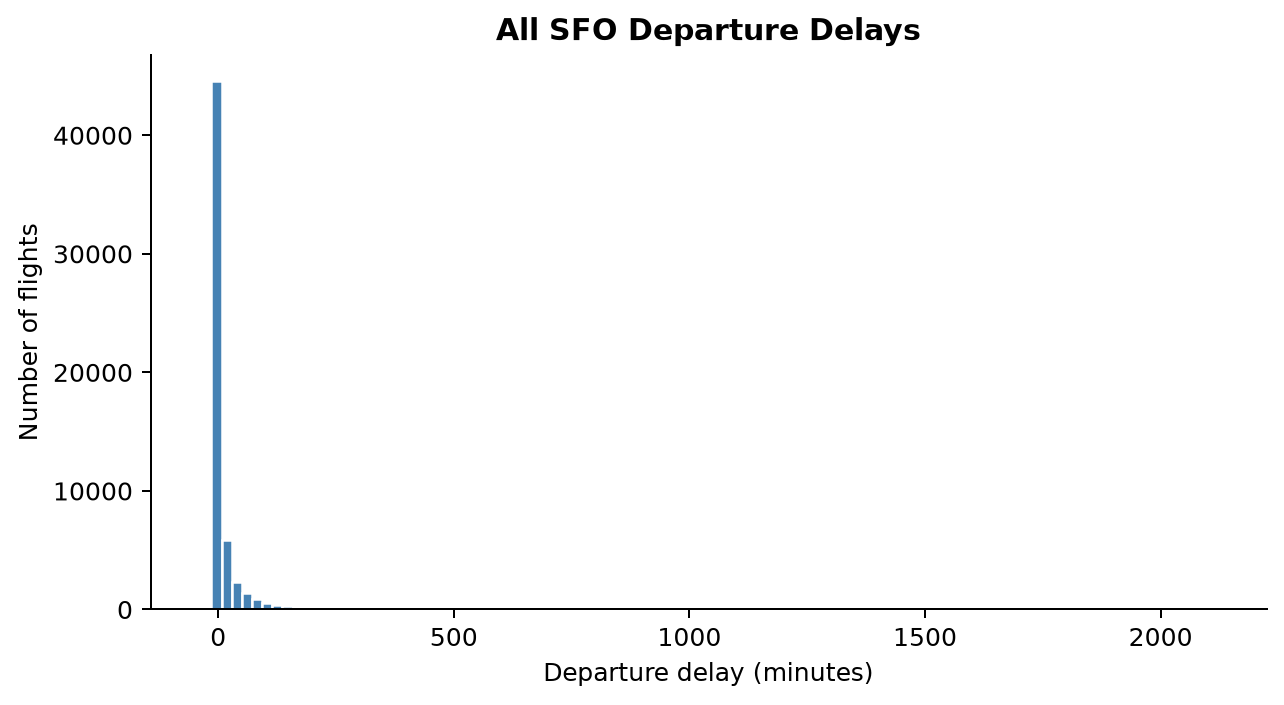

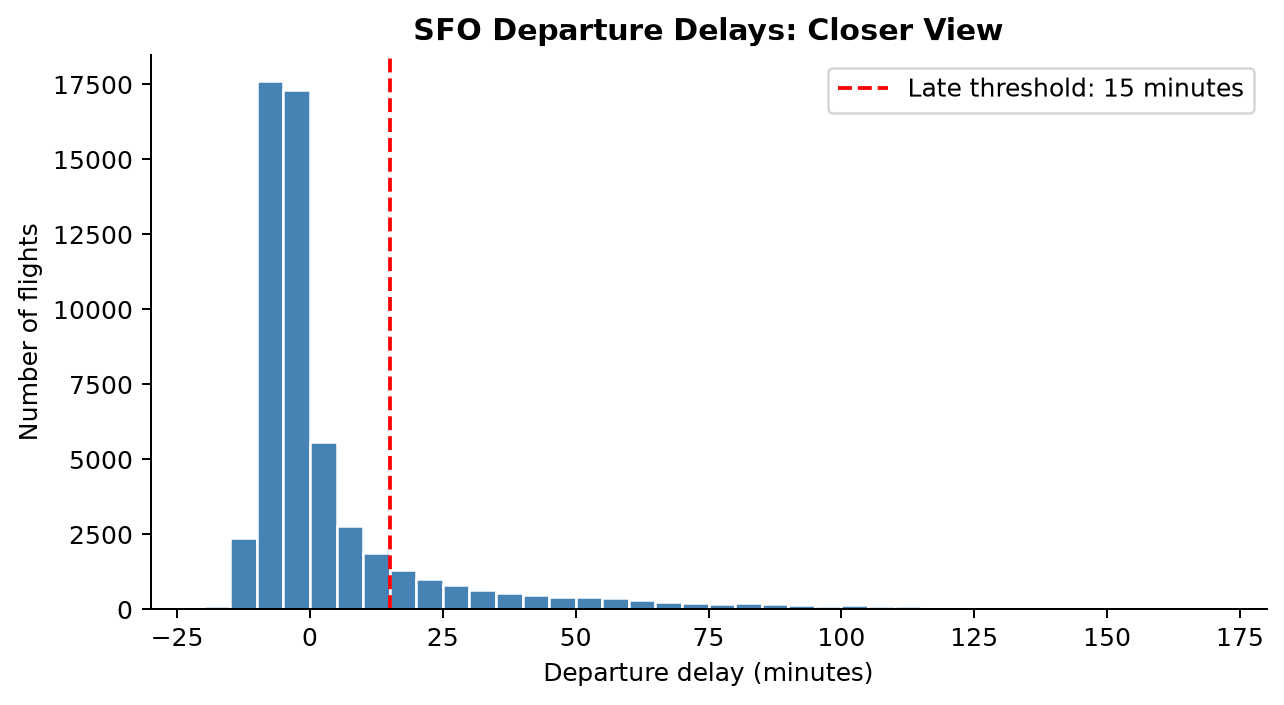

Flights outside the closer view: 610
Total flights: 57224
Early departures: 37425
Departures with zero delay: 2114
Earliest departure delay: -36.0 minutes
Longest departure delay: 2117.0 minutes


In [36]:
# Store the departure delays
D = df["dep_delay"]

# Display summary statistics
print(D.describe())

# Histogram showing the full range of delays
plt.figure(figsize=(8, 4))
plt.hist(D, bins=100, color="steelblue", edgecolor="white")

plt.title("All SFO Departure Delays")
plt.xlabel("Departure delay (minutes)")
plt.ylabel("Number of flights")

# Full departure-delay histogram
plt.savefig(figures_folder / "departure_delay_histogram.png",
            dpi=160, bbox_inches="tight")
plt.show()

# Histogram showing a closer view
# Use 5-minute intervals from -30 to 180 minutes
plt.figure(figsize=(8, 4))
plt.hist(
    D,
    bins=range(-30, 181, 5),
    color="steelblue",
    edgecolor="white"
)

# Mark the 15-minute late threshold
plt.axvline(
    15,
    color="red",
    linestyle="--",
    label="Late threshold: 15 minutes"
)

plt.title("SFO Departure Delays: Closer View")
plt.xlabel("Departure delay (minutes)")
plt.ylabel("Number of flights")
plt.xlim(-30, 180)
plt.legend()

# Closer-view histogram
plt.savefig(figures_folder / "departure_delay_zoom.png",
            dpi=160, bbox_inches="tight")
plt.show()

# Count flights outside the closer view
below_view = len(df[df["dep_delay"] < -30])
above_view = len(df[df["dep_delay"] > 180])

print("Flights outside the closer view:", below_view + above_view)

# Count early and exactly on-time departures
early_n = len(df[df["dep_delay"] < 0])
zero_n = len(df[df["dep_delay"] == 0])

print("Total flights:", len(df))
print("Early departures:", early_n)
print("Departures with zero delay:", zero_n)
print("Earliest departure delay:", D.min(), "minutes")
print("Longest departure delay:", D.max(), "minutes")

## 5. Fit a lognormal only to positive delays
Let X denote D conditional on D > 0. Fix the lognormal location at zero:
ln(X) ~ Normal(μ, σ²), with maximum-likelihood μ = mean(ln X) and σ = std(ln X, ddof=0).
SciPy's shape = σ and scale = exp(μ). This is a continuous approximation to minute-valued observations.
Save p0 = count(D > 0)/N for Week 3. The fitted model describes positive delays only; p0 is not a mass at zero.
No full-distribution model is supplied for D ≤ 0.

Flights with positive delays: 17685
Total flights: 57224
P(D > 0) = 0.309
Mu: 2.7976
Sigma: 1.426
Scale: 16.4049


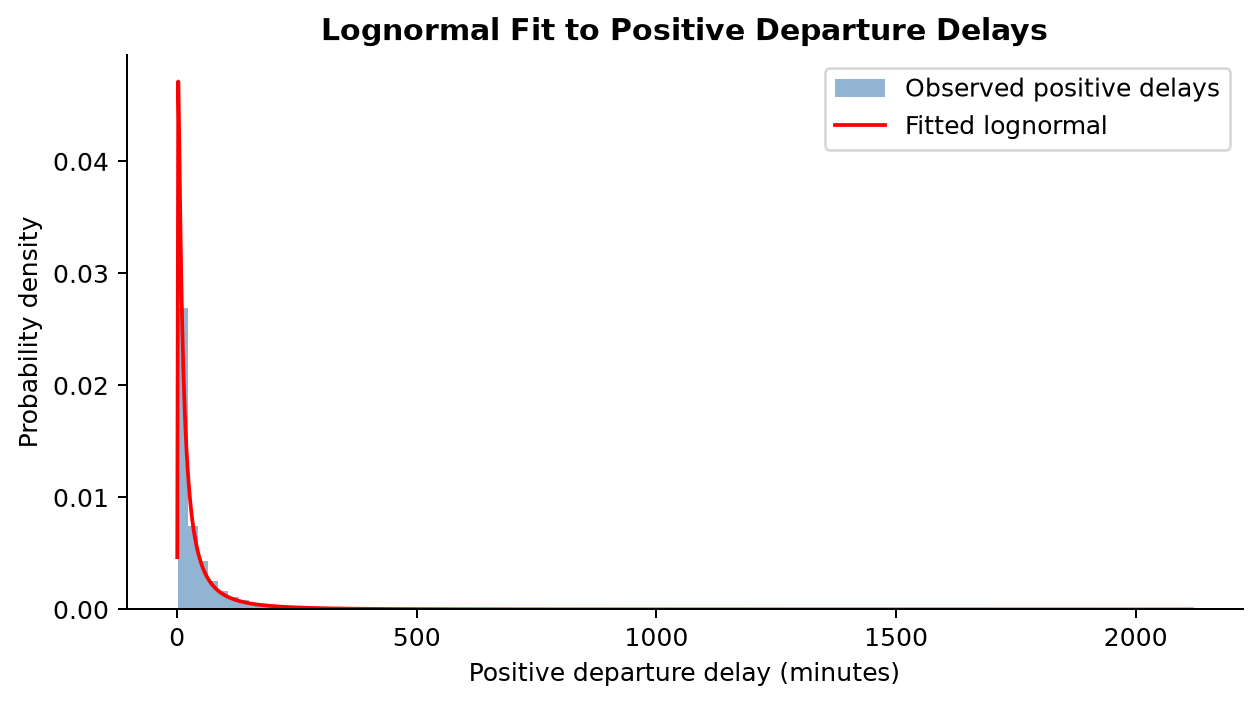

In [37]:
# Keep only delays greater than zero
positive = D[D > 0]

# Count the positive delays
n_positive = len(positive)

# Calculate the proportion of flights with a positive delay
N = len(df)
p0 = n_positive / N

print("Flights with positive delays:", n_positive)
print("Total flights:", N)
print("P(D > 0) =", round(p0, 4))

# Take the natural logarithm of the positive delays
log_delays = np.log(positive)

# Calculate the mean and standard deviation of the log delays
mu = log_delays.mean()
sigma = log_delays.std(ddof=0)

# Convert mu to the scale used by SciPy
scale = np.exp(mu)

# Create the fitted lognormal model
model = stats.lognorm(s=sigma, loc=0, scale=scale)

print("Mu:", round(mu, 4))
print("Sigma:", round(sigma, 4))
print("Scale:", round(scale, 4))

# Draw the positive-delay histogram
plt.figure(figsize=(8, 4))

plt.hist(
    positive,
    bins=100,
    density=True,
    alpha=0.6,
    color="steelblue",
    label="Observed positive delays"
)

# Create delay values for drawing the fitted curve
x = np.linspace(0.1, positive.max(), 1000)

# Draw the fitted lognormal curve
plt.plot(
    x,
    model.pdf(x),
    color="red",
    label="Fitted lognormal"
)

plt.title("Lognormal Fit to Positive Departure Delays")
plt.xlabel("Positive departure delay (minutes)")
plt.ylabel("Probability density")
plt.legend()


# Positive-delay lognormal fit
plt.savefig(figures_folder / "positive_delay_fit.png",
            dpi=160, bbox_inches="tight")
plt.show()

## 6. QQ plot and assumption check
Use plotting positions (i − 0.5)/n for sorted positive observations. The horizontal axis is the fitted
lognormal quantile; the vertical axis is the observed delay. Points above y=x mean that the model
underpredicts that quantile; points below it mean overprediction. Highlight the top 1% and label
the observed-versus-model 50th, 90th, 99th, and 99.9th percentiles.
The zoom makes deviations in the bulk visible while the full panel retains the extremes.

,Percentile,Fitted delay,Observed delay
0,50.0,16.404911,17.000
1,90.0,102.010913,102.000
2,99.0,452.580041,310.160
3,99.9,1345.159281,844.476


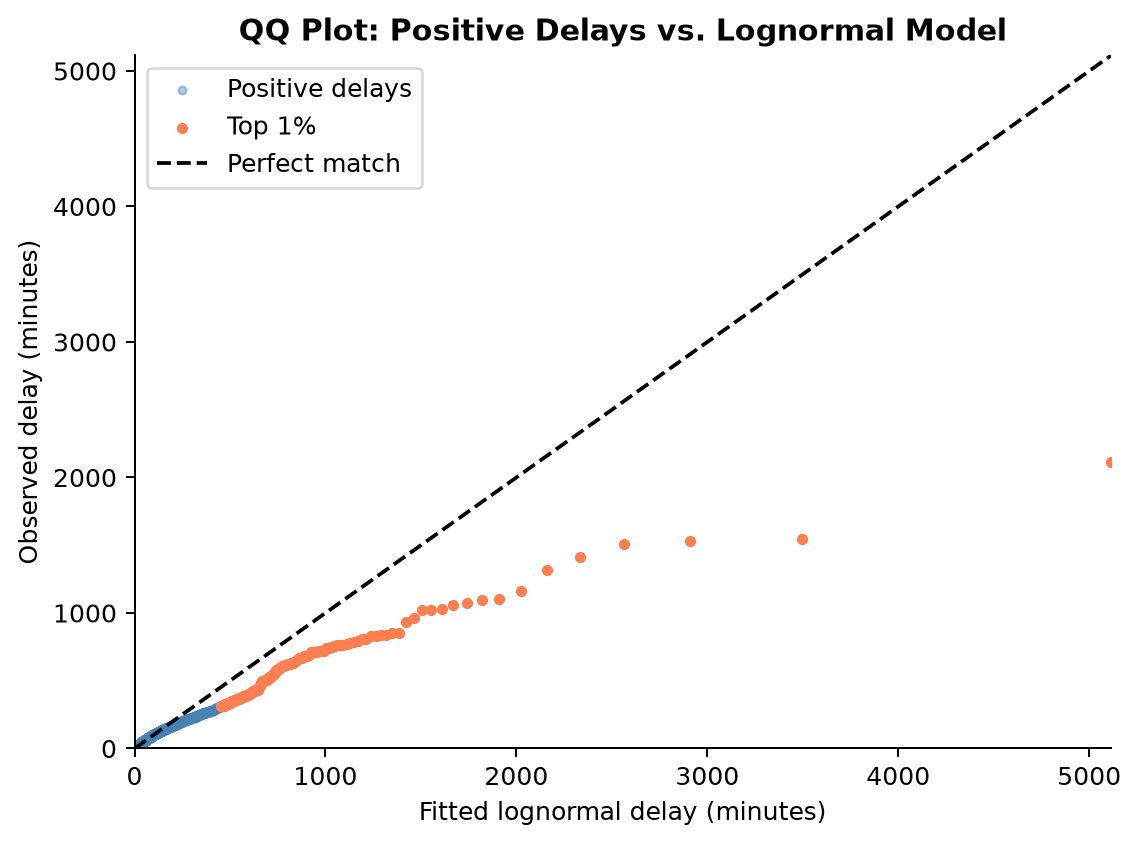

In [38]:
# Sort the positive delays from smallest to largest
observed = np.sort(positive)

# Assign a probability position to each observed delay
n_positive = len(positive)
q = (np.arange(1, n_positive + 1) - 0.5) / n_positive

# Find the model's predicted delay at each probability
theoretical = model.ppf(q)

# Make a table comparing a few important percentiles
probs = [0.50, 0.90, 0.99, 0.999]

qq_summary = pd.DataFrame({
    "Percentile": [50, 90, 99, 99.9],
    "Fitted delay": model.ppf(probs),
    "Observed delay": np.quantile(positive, probs)
})

display(qq_summary)

# Draw the QQ plot
plt.figure(figsize=(7, 5))

plt.scatter(
    theoretical,
    observed,
    s=10,
    alpha=0.4,
    color="steelblue",
    label="Positive delays"
)

# Highlight the largest 1% of observations
plt.scatter(
    theoretical[q >= 0.99],
    observed[q >= 0.99],
    s=12,
    color="coral",
    label="Top 1%"
)

# Find a limit that includes both sets of values
limit = max(theoretical.max(), observed.max())

# Draw the diagonal representing a perfect match
plt.plot(
    [0, limit],
    [0, limit],
    color="black",
    linestyle="--",
    label="Perfect match"
)

plt.xlim(0, limit)
plt.ylim(0, limit)
plt.title("QQ Plot: Positive Delays vs. Lognormal Model")
plt.xlabel("Fitted lognormal delay (minutes)")
plt.ylabel("Observed delay (minutes)")
plt.legend()

# QQ plot
plt.savefig(figures_folder / "lognormal_qq.png",
            dpi=160, bbox_inches="tight")
plt.show()

## 7. Joint carrier/lateness table and both marginals
Counts n(c,l) are divided by the same N to obtain P(C=c,L=l). Row sums give P(C=c);
column sums give P(L=l). These are **joint probabilities**, not within-carrier percentages.
Each marginal sums to one. Stop here: conditional probabilities belong to Week 2.

In [39]:
# Count not-late and late flights for each carrier
# margins=True adds a Total row and column
counts_margins = pd.crosstab(
    df["carrier"],
    df["late"],
    margins=True,
    margins_name="Total"
)

# Give the columns clearer names
counts_margins = counts_margins.rename(columns={
    0: "Not late",
    1: "Late"
})

print("Flight counts:")
display(counts_margins)

# Divide every count by the total number of flights
N = len(df)
joint_margins = counts_margins / N

print("Joint probabilities and marginals:")
display(joint_margins.round(4))

# Display the carrier marginal probabilities
# Leave out the final Total row
carrier_marginal = joint_margins["Total"].drop("Total")

print("Carrier marginal probabilities:")
print(carrier_marginal)
print("Sum:", carrier_marginal.sum())

# Display the lateness marginal probabilities
not_late_probability = joint_margins.loc["Total", "Not late"]
late_probability = joint_margins.loc["Total", "Late"]

print("\nNot-late probability:", not_late_probability)
print("Late probability:", late_probability)
print("Sum:", not_late_probability + late_probability)

Flight counts:


late,Not late,Late,Total
carrier,,,
AA,3862,806,4668
AS,3404,717,4121
B6,1396,261,1657
DL,4272,868,5140
F9,1295,502,1797
HA,309,62,371
OO,11800,2319,14119
UA,19132,3185,22317
WN,2196,838,3034


Joint probabilities and marginals:


late,Not late,Late,Total
carrier,,,
AA,0.0675,0.0141,0.0816
AS,0.0595,0.0125,0.0720
B6,0.0244,0.0046,0.0290
DL,0.0747,0.0152,0.0898
F9,0.0226,0.0088,0.0314
HA,0.0054,0.0011,0.0065
OO,0.2062,0.0405,0.2467
UA,0.3343,0.0557,0.3900
WN,0.0384,0.0146,0.0530


Carrier marginal probabilities:
carrier
AA    0.081574
AS    0.072015
B6    0.028956
DL    0.089822
F9    0.031403
HA    0.006483
OO    0.246732
UA    0.389994
WN    0.053020
Name: Total, dtype: float64
Sum: 1.0

Not-late probability: 0.8329721795051027
Late probability: 0.16702782049489726
Sum: 1.0


## 8. Save reusable results and a concise interpretation
The notebook exports the cleaned rows, counts, joint probabilities, fit parameters, and source hashes.
The interpretation below is calculated from these data, so it stays consistent when rerun.
Read the QQ figures and revise the discussion in your own words before submitting.

In [40]:
# Summarize lateness
print("SFO departures: January–May 2025")
print("Total flights:", N)
print("Late flights:", late_n)
print("Percent late:", round(p_late * 100, 2), "%")
print("Early departures:", early_n)

# Summarize departure delays
print("\nDeparture delays:")
print("Median:", np.median(D), "minutes")
print("Minimum:", D.min(), "minutes")
print("Maximum:", D.max(), "minutes")

# Compare the observed and fitted positive-delay medians
print("\nPositive delays:")
print("Number of flights:", n_positive)
print("Observed median:", round(np.median(positive), 1), "minutes")
print("Fitted median:", round(model.ppf(0.50), 1), "minutes")

# Display the percentile comparison from the QQ section
print("\nObserved and fitted delay percentiles:")
display(qq_summary.round(1))

# Keep the important results together for later weeks
summary = pd.DataFrame({
    "Result": [
        "Total flights",
        "Late flights",
        "Probability of lateness",
        "Flights with positive delays",
        "Probability of a positive delay",
        "Lognormal mu",
        "Lognormal sigma",
        "Lognormal scale"
    ],
    "Value": [
        N,
        late_n,
        p_late,
        n_positive,
        p0,
        mu,
        sigma,
        scale
    ]
})

display(summary)

SFO departures: January–May 2025
Total flights: 57224
Late flights: 9558
Percent late: 16.7 %
Early departures: 37425

Departure delays:
Median: -3.0 minutes
Minimum: -36.0 minutes
Maximum: 2117.0 minutes

Positive delays:
Number of flights: 17685
Observed median: 17.0 minutes
Fitted median: 16.4 minutes

Observed and fitted delay percentiles:


,Percentile,Fitted delay,Observed delay
0,50.0,16.4,17.0
1,90.0,102.0,102.0
2,99.0,452.6,310.2
3,99.9,1345.2,844.5


,Result,Value
0,Total flights,57224.000000
1,Late flights,9558.000000
2,Probability of lateness,0.167028
3,Flights with positive delays,17685.000000
4,Probability of a positive delay,0.309049
5,Lognormal mu,2.797581
6,Lognormal sigma,1.426005
7,Lognormal scale,16.404911


## 9. Export the one-page Week 1 deliverable
This page includes the histogram, QQ plot, joint table with both marginals, counts, and four interpretation sentences.
Both full-range diagnostic charts remain available above and in `results/figures/`.

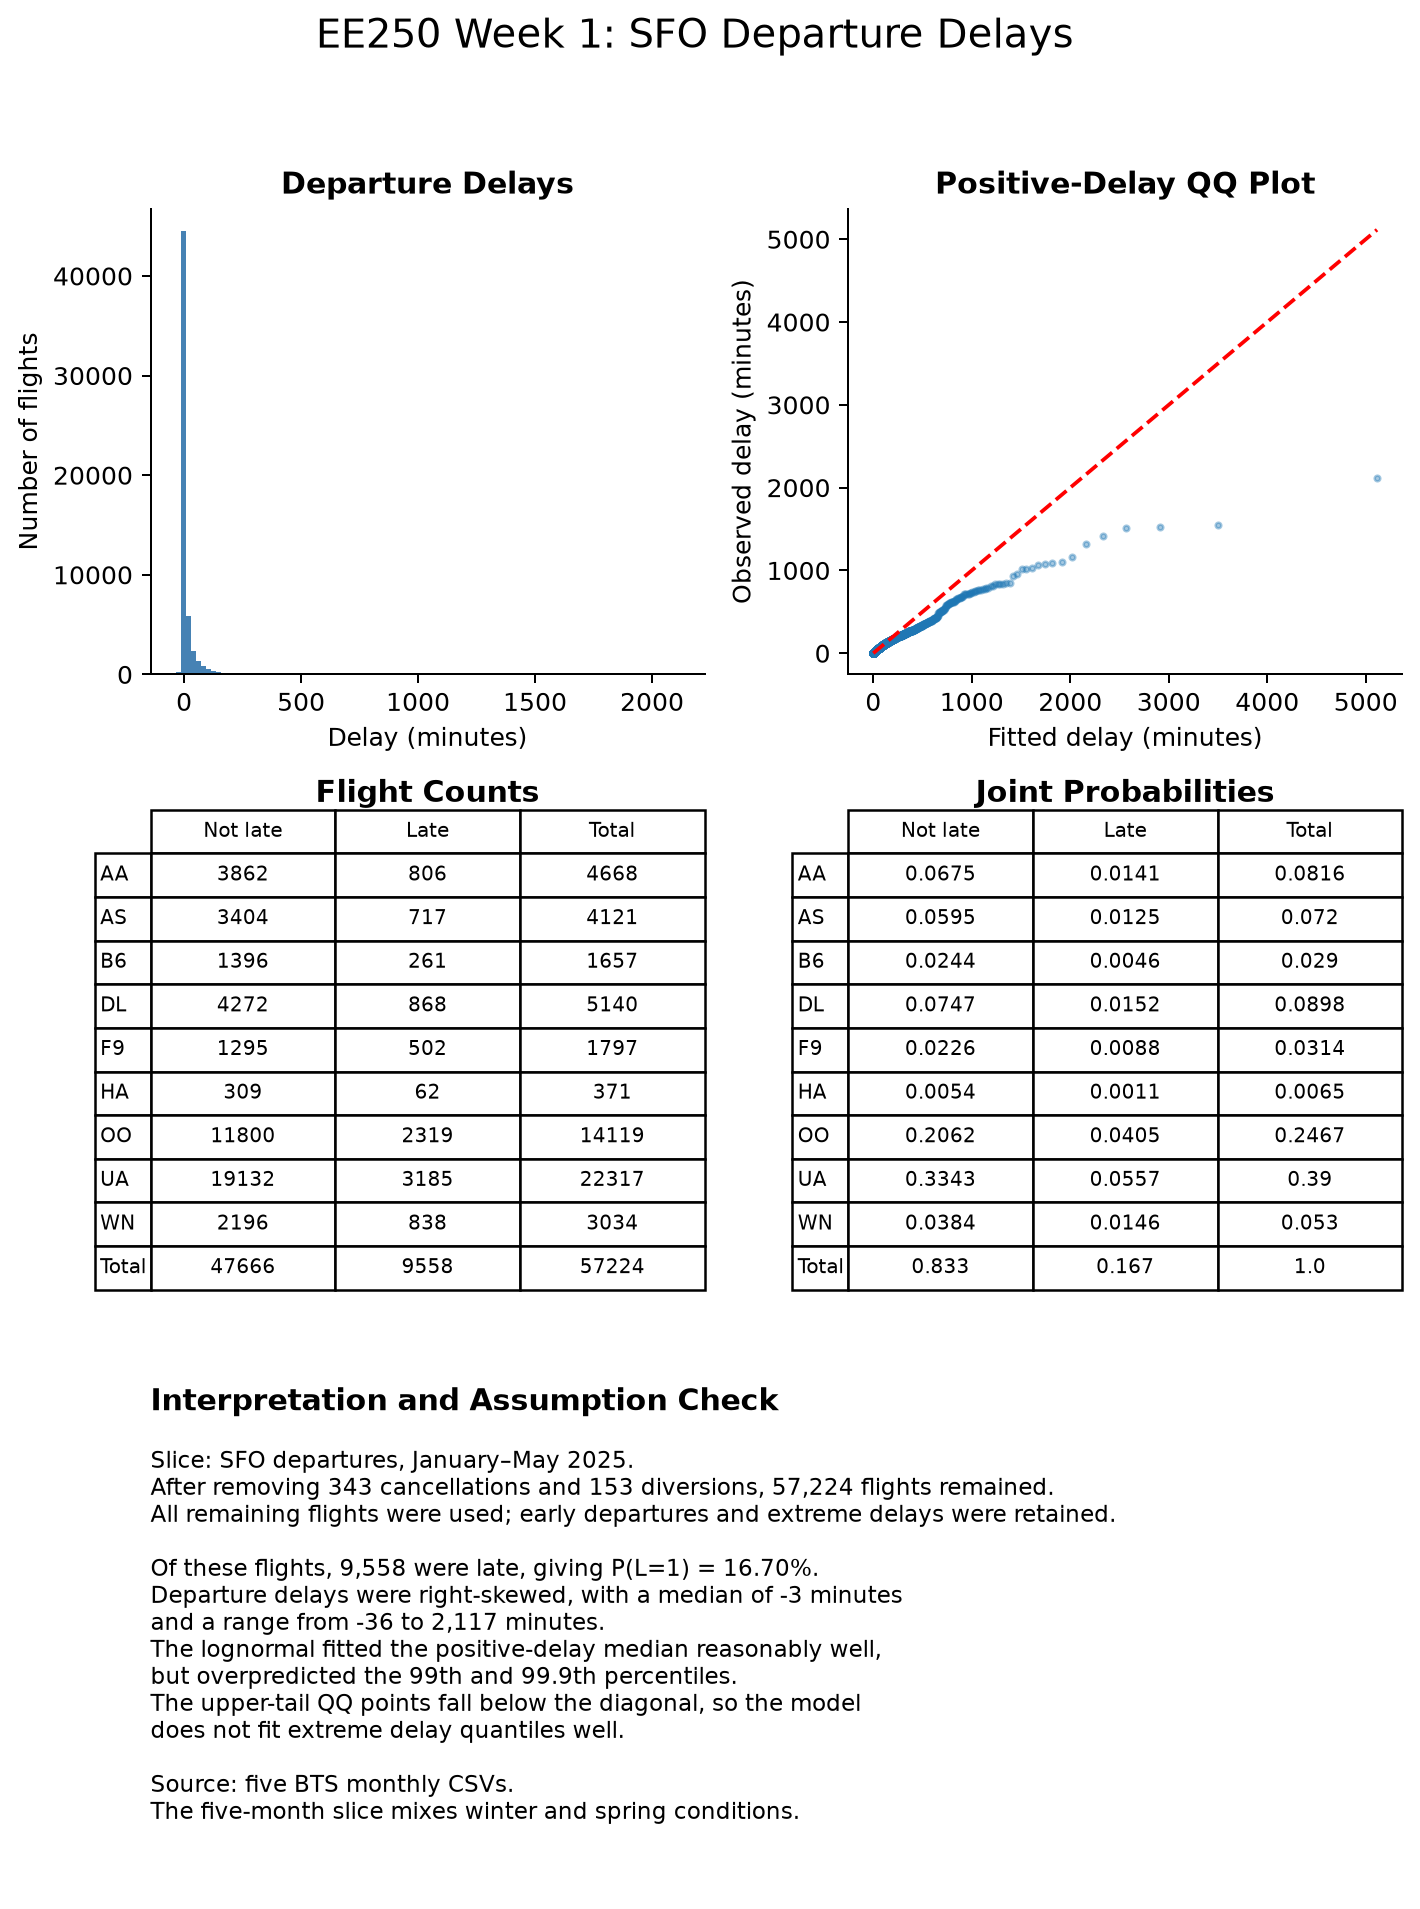

In [41]:
# Create a page-sized figure
plt.figure(figsize=(8.5, 11))
plt.suptitle("EE250 Week 1: SFO Departure Delays", fontsize=16)

# Top left: departure-delay histogram
plt.subplot(3, 2, 1)

plt.hist(D, bins=100, color="steelblue")
plt.title("Departure Delays")
plt.xlabel("Delay (minutes)")
plt.ylabel("Number of flights")

# Top right: QQ plot
plt.subplot(3, 2, 2)

plt.scatter(theoretical, observed, s=5, alpha=0.4)

limit = max(theoretical.max(), observed.max())
plt.plot([0, limit], [0, limit], "r--")

plt.title("Positive-Delay QQ Plot")
plt.xlabel("Fitted delay (minutes)")
plt.ylabel("Observed delay (minutes)")

# Middle left: carrier and lateness counts
plt.subplot(3, 2, 3)
plt.axis("off")
plt.title("Flight Counts")

count_table = plt.table(
    cellText=counts_margins.values,
    rowLabels=counts_margins.index,
    colLabels=counts_margins.columns,
    cellLoc="center",
    loc="center"
)

count_table.auto_set_font_size(False)
count_table.set_fontsize(8)
count_table.scale(1, 1.4)

# Middle right: joint probabilities and marginals
plt.subplot(3, 2, 4)
plt.axis("off")
plt.title("Joint Probabilities")

probability_table = plt.table(
    cellText=joint_margins.round(4).values,
    rowLabels=joint_margins.index,
    colLabels=joint_margins.columns,
    cellLoc="center",
    loc="center"
)

probability_table.auto_set_font_size(False)
probability_table.set_fontsize(8)
probability_table.scale(1, 1.4)

# Bottom: written findings
plt.subplot(3, 1, 3)
plt.axis("off")
plt.title("Interpretation and Assumption Check", loc="left")

interpretation = (
    "Slice: SFO departures, January–May 2025.\n"
    "After removing 343 cancellations and 153 diversions, 57,224 flights remained.\n"
    "All remaining flights were used; early departures and extreme delays were retained.\n\n"
    "Of these flights, 9,558 were late, giving P(L=1) = 16.70%.\n"
    "Departure delays were right-skewed, with a median of -3 minutes\n"
    "and a range from -36 to 2,117 minutes.\n"
    "The lognormal fitted the positive-delay median reasonably well,\n"
    "but overpredicted the 99th and 99.9th percentiles.\n"
    "The upper-tail QQ points fall below the diagonal, so the model\n"
    "does not fit extreme delay quantiles well.\n\n"
    "Source: five BTS monthly CSVs.\n"
    "The five-month slice mixes winter and spring conditions."
)

plt.text(0, 0.95, interpretation, fontsize=9, va="top")

# Adjust spacing and save the report
plt.tight_layout(rect=[0.04, 0.02, 0.98, 0.95])

plt.savefig("week1_report.pdf")
plt.savefig("week1_report.png", dpi=160)

plt.show()

# 10. Save all tables for easier viewing


In [42]:
# Save tables without the extra row numbers
lateness.to_csv(tables_folder / "lateness.csv", index=False)
qq_summary.to_csv(tables_folder / "qq_quantiles.csv", index=False)
summary.to_csv(tables_folder / "week1_summary.csv", index=False)

# Keep the row labels because they identify carriers and totals
counts_margins.to_csv(tables_folder / "carrier_lateness_counts.csv")
joint_margins.to_csv(tables_folder / "carrier_lateness_joint.csv")

## Week 1 completion checklist
- [x] Explicit airport/month slice and sample size; fixed seed and cleaning counts
- [x] Lateness chart and P(L=1) with numerator/denominator
- [x] Histogram with negative departures and full right tail
- [x] Positive-delay fit only; saved p0, μ, σ, location, scale
- [x] QQ plots with highlighted extreme quantiles and interpretation
- [x] Carrier/lateness counts, joint probabilities, both checked marginals
- [x] One-page report exported; reusable cleaned data and Week 1 results saved

**Before submission:** add your team names to the report title if needed, read the interpretation,
and note that the five-month slice spans winter and spring; seasonal conditions may differ.
Do not add Week 2 conditional tables to this deliverable.